# 파트 B. 2표본 멘델리안 무작위분석 (TwoSampleMR)
**연구 질문**
1. 흡연, BMI는 류마티스관절염의 원인인가? (파트 A의 관찰 결과를 인과적으로 검증)
2. 류마티스관절염·루푸스에 대한 유전적 소인은 알츠하이머병 위험을 높이는가?

**실행 환경:** R 커널 (Colab: *런타임 → 런타임 유형 변경 → R*)



In [1]:
# 패키지 설치 (처음 한 번만)
if (!requireNamespace("TwoSampleMR", quietly = TRUE)) {
  install.packages("remotes")
  remotes::install_github("MRCIEU/TwoSampleMR")
}
for (p in c("dplyr", "ggplot2")) if (!requireNamespace(p, quietly = TRUE)) install.packages(p)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




MRMix       (NA -> 56afdb2bc...) [GitHub]
MRPRESSO    (NA -> 3e3c92d7e...) [GitHub]
RadialMR    (NA -> 7ca35c052...) [GitHub]
iterators   (NA -> 1.0.14      ) [CRAN]
GPArotation (NA -> 2026.8-2    ) [CRAN]
mnormt      (NA -> 2.1.2       ) [CRAN]
RcppEigen   (NA -> 0.3.4.0.2   ) [CRAN]
shape       (NA -> 1.4.6.1     ) [CRAN]
foreach     (NA -> 1.5.2       ) [CRAN]
psych       (NA -> 2.6.9       ) [CRAN]
pbapply     (NA -> 1.7-5       ) [CRAN]
ieugwasr    (NA -> 1.2.0       ) [CRAN]
gridExtra   (NA -> 2.3.1       ) [CRAN]
glmnet      (NA -> 5.1         ) [CRAN]
cowplot     (NA -> 1.2.0       ) [CRAN]


── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpiGgUXZ/remotes4a713062fc7/gqi-MRMix-56afdb2/DESCRIPTION’ ... OK
* preparing ‘MRMix’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘MRMix_0.1.0.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpiGgUXZ/remotes4a743827c2c/rondolab-MR-PRESSO-3e3c92d/DESCRIPTION’ ... OK
* preparing ‘MRPRESSO’:
* checking DESCRIPTION meta-information ... OK
* installing the package (it is needed to process help pages)
* saving partial Rd database
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* looking to see if a ‘data/datalist’ file should be added
* building ‘MRPRESSO_1.0.tar.gz’



...

Installing 3 packages: lazyeval, crosstalk, plotly

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpiGgUXZ/remotes4a7648c5195/WSpiller-RadialMR-7ca35c0/DESCRIPTION’ ... OK
* preparing ‘RadialMR’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘RadialMR_1.2.5.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing 12 packages: iterators, GPArotation, mnormt, RcppEigen, shape, foreach, psych, pbapply, ieugwasr, gridExtra, glmnet, cowplot

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Skipping install of 'MRMix' from a github remote, the SHA1 (56afdb2b) has not changed since last install.
  Use `force = TRUE` to force installation

Skipping install of 'MRPRESSO' from a github remote, the SHA1 (3e3c92d7) has not changed since last install.
  Use `force = TRUE` to force installation

Skipping install of 'RadialMR' from a github remote, the SHA1 (7ca35c05) has not changed since last install.
  Use `force = TRUE` to force installation



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpiGgUXZ/remotes4a71b5928b7/MRCIEU-TwoSampleMR-5e93ee7/DESCRIPTION’ ... OK
* preparing ‘TwoSampleMR’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘TwoSampleMR_0.7.13.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(TwoSampleMR)
library(ieugwasr)
library(dplyr)
library(ggplot2)

Sys.setenv(OPENGWAS_JWT = "")
stopifnot(get_opengwas_jwt() != "")

TwoSampleMR version 0.7.13 


 [>] New authentication requirements: https://mrcieu.github.io/ieugwasr/articles/guide.html#authentication.

 [>] Major upgrades to our servers completed to improve service and stability.

 [>] We need your help to shape our emerging roadmap!

     Please take 2 minutes to give us feedback -

     https://forms.office.com/e/eSr7EFAfCG

OpenGWAS updates:

  Date: 2024-05-17

  [>] OpenGWAS is growing!

  [>] Please take 2 minutes to give us feedback -

  [>] It will help directly shape our emerging roadmap

  [>] https://forms.office.com/e/eSr7EFAfCG


Attaching package: ‘ieugwasr’


The following object is masked from ‘package:TwoSampleMR’:

    ld_matrix



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 0. GWAS 선택
**선택 기준**
- 노출과 결과를 같은 인구집단(유럽계)으로 맞춤
- **표본 중복 최소화**: 흡연(GSCAN)·BMI(GIANT+UK Biobank) GWAS는 UK Biobank를 포함하므로, 결과 GWAS는 UK Biobank가 없는 컨소시엄 자료를 주 분석으로 사용
  - 류마티스관절염: `ieu-a-832` (Okada 2014, 유럽계 약 5.8만 명, UKB 미포함)
  - 루푸스: `ebi-a-GCST003156` (Bentham 2015, 유럽계 약 1.4만 명)
  - UK Biobank·FinnGen 기반 대규모 GWAS(`ebi-a-GCST90018910` 등)는 **민감도 분석**으로 비교
- 알츠하이머병: `ebi-a-GCST90027158` (Bellenguez 2022)

아래 셀에서 각 ID의 표본 수, 인구집단, 저자를 꼭 확인하세요.

In [3]:
ID <- list(
  smoking   = "ieu-b-4877",          # 흡연 시작 여부 (GSCAN, Liu 2019)
  bmi       = "ieu-b-40",            # BMI (Yengo 2018)
  ra        = "ieu-a-832",           # 류마티스관절염 (Okada 2014, 유럽계) - 주 분석
  ra_large  = "ebi-a-GCST90018910",  # 류마티스관절염 (Sakaue 2021, 유럽계) - 민감도 분석
  sle       = "ebi-a-GCST003156",    # 루푸스 (Bentham 2015, 유럽계)
  ad        = "ebi-a-GCST90027158"   # 알츠하이머병 (Bellenguez 2022)
)

# ID가 실제로 존재하는지, 무엇인지 확인
info <- gwasinfo(unlist(ID))
info %>% select(any_of(c("id", "trait", "author", "year", "population", "sample_size", "ncase", "ncontrol")))

id,trait,author,year,population,sample_size,ncase,ncontrol
<chr>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<int>
ieu-b-4877,smoking initiation,Liu M,2019,European,607291,311629,321173
ieu-b-40,body mass index,"Yengo, L",2018,European,681275,NA,NA
ieu-a-832,Rheumatoid arthritis,Okada Y,2014,European,58284,14361,43923
ebi-a-GCST90018910,Rheumatoid arthritis,Sakaue S,2021,European,417256,8255,409001
ebi-a-GCST003156,Systemic lupus erythematosus,Bentham J,2015,European,14267,5201,9066
ebi-a-GCST90027158,Alzheimer's disease,Bellenguez C,2022,European,487511,39106,46828


## 1. 분석 함수
지난번 오류(`도구 수: | 평균 F: NaN` → `split.default` 에러)는 흡연 ID가 placeholder여서 **도구변수가 0개**로 추출됐기 때문입니다. 아래 함수는 단계마다 개수를 확인하고, 문제가 있으면 원인을 알려주며 멈춥니다.

1. 도구변수 선택 (p < 5×10⁻⁸) + 연관불균형 정리 (r² < 0.001, 10 Mb)
2. (선택) HLA 영역 제외: 6번 염색체 25–34 Mb (GRCh37)
3. 도구 강도: F 통계량 (10 이상 권장)
4. 결과 GWAS에서 같은 변이 추출(없으면 대리 변이 사용) + 대립유전자 맞추기
5. IVW, MR-Egger, 가중 중앙값, 가중 최빈값
6. 이질성, Egger 절편, leave-one-out, Steiger 방향성

In [4]:
safe <- function(expr) tryCatch(expr, error = function(e) { message("  (건너뜀) ", conditionMessage(e)); NULL })

run_mr <- function(exposure_id, outcome_id, drop_hla = FALSE, label = "") {
  message("\n==== ", label, " : ", exposure_id, " -> ", outcome_id, " ====")

  # 1) 도구변수
  exp_dat <- extract_instruments(outcomes = exposure_id, p1 = 5e-8,
                                 clump = TRUE, r2 = 0.001, kb = 10000)
  if (is.null(exp_dat) || nrow(exp_dat) == 0)
    stop("도구변수가 0개입니다. ID(", exposure_id, ")와 토큰을 확인하세요.")

  # 2) HLA 제외
  if (drop_hla) {
    n0 <- nrow(exp_dat)
    exp_dat <- exp_dat %>%
      filter(!(as.character(chr.exposure) == "6" &
               as.numeric(pos.exposure) > 25e6 & as.numeric(pos.exposure) < 34e6))
    message("  HLA 영역 변이 ", n0 - nrow(exp_dat), "개 제외")
  }

  # 3) 도구 강도
  exp_dat$F <- (exp_dat$beta.exposure / exp_dat$se.exposure)^2
  message("  도구 수: ", nrow(exp_dat), " | 평균 F: ", round(mean(exp_dat$F), 1),
          " | 최소 F: ", round(min(exp_dat$F), 1))

  # 4) 결과 자료 + 정렬
  out_dat <- extract_outcome_data(snps = exp_dat$SNP, outcomes = outcome_id,
                                  proxies = TRUE, rsq = 0.8)
  if (is.null(out_dat) || nrow(out_dat) == 0)
    stop("결과 GWAS(", outcome_id, ")에서 일치하는 변이를 찾지 못했습니다.")
  dat <- harmonise_data(exp_dat, out_dat, action = 2)
  dat <- dat %>% filter(mr_keep)
  message("  정렬 후 분석 변이: ", nrow(dat))
  if (nrow(dat) < 3) stop("분석 가능한 변이가 3개 미만입니다.")

  # 5) 추정
  res <- mr(dat, method_list = c("mr_ivw", "mr_egger_regression",
                                 "mr_weighted_median", "mr_weighted_mode"))

  # 6) 민감도 분석 (일부 실패해도 나머지는 계속)
  list(
    label         = label,
    dat           = dat,
    result        = generate_odds_ratios(res) %>% mutate(question = label),
    heterogeneity = safe(mr_heterogeneity(dat)),
    pleiotropy    = safe(mr_pleiotropy_test(dat)),
    loo           = safe(mr_leaveoneout(dat)),
    steiger       = safe(directionality_test(dat))
  )
}

show_mr <- function(x) {
  print(x$result %>% select(method, nsnp, or, or_lci95, or_uci95, pval), digits = 3)
  if (!is.null(x$pleiotropy))    print(x$pleiotropy %>% select(egger_intercept, se, pval))
  if (!is.null(x$heterogeneity)) print(x$heterogeneity %>% select(method, Q, Q_df, Q_pval))
  if (!is.null(x$steiger))       print(x$steiger %>% select(correct_causal_direction, steiger_pval))
  invisible(x)
}

results <- list()   # 성공한 분석만 모음
add <- function(name, ...) {
  r <- tryCatch(run_mr(...), error = function(e) { message("❌ ", conditionMessage(e)); NULL })
  if (!is.null(r)) { results[[name]] <<- r; show_mr(r) }
  invisible(r)
}

## 2. 질문 1: 흡연·BMI → 류마티스관절염
- 흡연 노출은 *흡연 시작 여부(이진)* GWAS이므로, 효과는 "흡연 시작의 유전적 소인 로그 오즈 1 증가당"으로 해석합니다.
- BMI 효과는 BMI 1 SD(약 4.8 kg/m²) 증가당입니다.

In [5]:
add("smk_ra",       ID$smoking, ID$ra,       label = "Smoking -> RA")
add("smk_ra_large", ID$smoking, ID$ra_large, label = "Smoking -> RA (large GWAS, overlap)")


==== Smoking -> RA : ieu-b-4877 -> ieu-a-832 ====

  도구 수: 93 | 평균 F: 42.1 | 최소 F: 29.8

Extracting data for 93 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 2

Querying variant chunk 2 of 2

Finding proxies for 15 SNPs in outcome ieu-a-832

Extracting data for 15 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising smoking initiation || id:ieu-b-4877 (ieu-b-4877) and Rheumatoid arthritis || id:ieu-a-832 (ieu-a-832)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs10159545, rs1160685, rs12356821, rs13145728, rs1555445, rs1565735, rs1937443, rs2107300, rs222449, rs2672851, rs4759228, rs578584, rs6508144, rs6788098, rs72896886, rs7585579, rs7921378, rs9423279, rs9835772

  정렬 후 분석 변이: 68

Analysing 'ieu-b-4877' on 'ieu-a-832'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Pl

                     method nsnp   or or_lci95 or_uci95    pval
1 Inverse variance weighted   68 1.51    1.177     1.95 0.00123
2                  MR Egger   68 1.13    0.332     3.85 0.84589
3           Weighted median   68 1.58    1.123     2.21 0.00854
4             Weighted mode   68 1.95    0.933     4.07 0.08059
  egger_intercept         se      pval
1     0.007614504 0.01593355 0.6343066
                     method        Q Q_df       Q_pval
1                  MR Egger 108.6068   66 0.0007483907
2 Inverse variance weighted 108.9826   67 0.0009074039
  correct_causal_direction steiger_pval
1                     TRUE 2.216626e-06



==== Smoking -> RA (large GWAS, overlap) : ieu-b-4877 -> ebi-a-GCST90018910 ====

  도구 수: 93 | 평균 F: 42.1 | 최소 F: 29.8

Extracting data for 93 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 2

Querying variant chunk 2 of 2

Finding proxies for 1 SNPs in outcome ebi-a-GCST90018910

Extracting data for 1 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising smoking initiation || id:ieu-b-4877 (ieu-b-4877) and Rheumatoid arthritis || id:ebi-a-GCST90018910 (ebi-a-GCST90018910)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs1160685, rs1555445, rs1937443, rs2672851, rs6508144, rs7585579, rs7921378

  정렬 후 분석 변이: 85

Analysing 'ieu-b-4877' on 'ebi-a-GCST90018910'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor()

                     method nsnp   or or_lci95 or_uci95   pval
1 Inverse variance weighted   85 1.16    1.014     1.34 0.0314
2                  MR Egger   85 1.02    0.507     2.06 0.9489
3           Weighted median   85 1.21    1.011     1.45 0.0372
4             Weighted mode   85 1.23    0.845     1.79 0.2827
  egger_intercept          se      pval
1      0.00341776 0.009252768 0.7127874
                     method        Q Q_df     Q_pval
1                  MR Egger 105.7746   83 0.04663036
2 Inverse variance weighted 105.9485   84 0.05311542
  correct_causal_direction  steiger_pval
1                     TRUE 5.411021e-192


In [6]:
add("bmi_ra",       ID$bmi, ID$ra,       label = "BMI -> RA")
add("bmi_ra_large", ID$bmi, ID$ra_large, label = "BMI -> RA (large GWAS, overlap)")


==== BMI -> RA : ieu-b-40 -> ieu-a-832 ====

  도구 수: 501 | 평균 F: 75.2 | 최소 F: 28.6

Extracting data for 501 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 8

Querying variant chunk 2 of 8

Querying variant chunk 3 of 8

Querying variant chunk 4 of 8

Querying variant chunk 5 of 8

Querying variant chunk 6 of 8

Querying variant chunk 7 of 8

Querying variant chunk 8 of 8

Finding proxies for 89 SNPs in outcome ieu-a-832

Extracting data for 89 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 2

Querying variant chunk 2 of 2

Harmonising body mass index || id:ieu-b-40 (ieu-b-40) and Rheumatoid arthritis || id:ieu-a-832 (ieu-a-832)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs10838202, rs10858334, rs10887578, rs10962550, rs11044430, rs11505821, rs11736228, rs12439829, rs12517185, rs1285997, rs12905439, rs12922346, rs12998411, rs13047416, rs138289, rs1462496, rs1521527, rs17379561, rs1

                     method nsnp   or or_lci95 or_uci95     pval
1 Inverse variance weighted  427 1.24    1.059     1.45 0.007664
2                  MR Egger  427 1.03    0.679     1.55 0.898395
3           Weighted median  427 1.53    1.216     1.92 0.000275
4             Weighted mode  427 2.29    1.514     3.46 0.000101
  egger_intercept          se      pval
1      0.00331425 0.003442396 0.3362083
                     method        Q Q_df       Q_pval
1                  MR Egger 694.4759  425 2.694542e-15
2 Inverse variance weighted 695.9906  426 2.565594e-15
  correct_causal_direction  steiger_pval
1                     TRUE 1.766523e-119



==== BMI -> RA (large GWAS, overlap) : ieu-b-40 -> ebi-a-GCST90018910 ====

  도구 수: 501 | 평균 F: 75.2 | 최소 F: 28.6

Extracting data for 501 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 8

Querying variant chunk 2 of 8

Querying variant chunk 3 of 8

Querying variant chunk 4 of 8

Querying variant chunk 5 of 8

Querying variant chunk 6 of 8

Querying variant chunk 7 of 8

Querying variant chunk 8 of 8

Finding proxies for 3 SNPs in outcome ebi-a-GCST90018910

Extracting data for 3 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising body mass index || id:ieu-b-40 (ieu-b-40) and Rheumatoid arthritis || id:ebi-a-GCST90018910 (ebi-a-GCST90018910)

Removing the following SNPs for incompatible alleles:
rs705217, rs806600

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs10838202, rs10887578, rs12517185, rs13047416, rs138289, rs1462496, rs1521527, rs189843, rs2163188, rs2268082, rs2

                     method nsnp   or or_lci95 or_uci95     pval
1 Inverse variance weighted  481 1.37    1.247     1.50 2.76e-11
2                  MR Egger  481 1.05    0.833     1.33 6.69e-01
3           Weighted median  481 1.23    1.058     1.44 7.62e-03
4             Weighted mode  481 1.20    0.953     1.50 1.22e-01
  egger_intercept          se       pval
1     0.004679666 0.001956299 0.01713673
                     method        Q Q_df       Q_pval
1                  MR Egger 610.0967  479 4.387600e-05
2 Inverse variance weighted 617.3849  480 2.146183e-05
  correct_causal_direction steiger_pval
1                     TRUE            0


## 3. 질문 2: 자가면역 소인 → 알츠하이머병
- 자가면역질환 GWAS는 HLA 신호가 강해 **다면발현** 위험이 크므로 HLA 제외 분석과 비교합니다.
- 알츠하이머 GWAS의 APOE 영역(19번 염색체)은 노출 도구변수에 거의 포함되지 않지만, 결과 해석 시 유의합니다.

In [7]:
add("ra_ad",       ID$ra, ID$ad,                  label = "RA -> AD")
add("ra_ad_noHLA", ID$ra, ID$ad, drop_hla = TRUE, label = "RA -> AD (no HLA)")


==== RA -> AD : ieu-a-832 -> ebi-a-GCST90027158 ====

  도구 수: 44 | 평균 F: 104.1 | 최소 F: 29.8

Extracting data for 44 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Finding proxies for 3 SNPs in outcome ebi-a-GCST90027158

Extracting data for 3 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising Rheumatoid arthritis || id:ieu-a-832 (ieu-a-832) and Alzheimer's disease || id:ebi-a-GCST90027158 (ebi-a-GCST90027158)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs13330176, rs225433, rs2661798, rs34536443, rs35445178, rs3799963, rs4452313

  정렬 후 분석 변이: 37

Analysing 'ieu-a-832' on 'ebi-a-GCST90027158'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor() for any binary traits



                     method nsnp    or or_lci95 or_uci95     pval
1 Inverse variance weighted   37 0.956    0.935    0.977 5.64e-05
2                  MR Egger   37 0.931    0.905    0.956 9.51e-06
3           Weighted median   37 0.934    0.917    0.951 2.55e-13
4             Weighted mode   37 0.935    0.917    0.953 4.00e-08
  egger_intercept          se        pval
1     0.009402182 0.003299543 0.007288269
                     method         Q Q_df       Q_pval
1                  MR Egger  87.39783   35 2.260399e-06
2 Inverse variance weighted 107.67384   36 4.528800e-09
  correct_causal_direction steiger_pval
1                     TRUE            0



==== RA -> AD (no HLA) : ieu-a-832 -> ebi-a-GCST90027158 ====

  HLA 영역 변이 6개 제외

  도구 수: 38 | 평균 F: 64.1 | 최소 F: 29.8

Extracting data for 38 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Finding proxies for 1 SNPs in outcome ebi-a-GCST90027158

Extracting data for 1 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising Rheumatoid arthritis || id:ieu-a-832 (ieu-a-832) and Alzheimer's disease || id:ebi-a-GCST90027158 (ebi-a-GCST90027158)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs13330176, rs225433, rs2661798, rs34536443, rs3799963, rs4452313

  정렬 후 분석 변이: 32

Analysing 'ieu-a-832' on 'ebi-a-GCST90027158'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor() for any binary traits



                     method nsnp    or or_lci95 or_uci95  pval
1 Inverse variance weighted   32 1.002    0.971     1.03 0.905
2                  MR Egger   32 0.982    0.914     1.05 0.622
3           Weighted median   32 1.017    0.981     1.06 0.359
4             Weighted mode   32 1.021    0.978     1.07 0.346
  egger_intercept         se      pval
1     0.003115413 0.00510079 0.5459514
                     method        Q Q_df      Q_pval
1                  MR Egger 57.94121   30 0.001622641
2 Inverse variance weighted 58.66169   31 0.001934274
  correct_causal_direction  steiger_pval
1                     TRUE 2.848663e-221


In [8]:
add("sle_ad",       ID$sle, ID$ad,                  label = "SLE -> AD")
add("sle_ad_noHLA", ID$sle, ID$ad, drop_hla = TRUE, label = "SLE -> AD (no HLA)")


==== SLE -> AD : ebi-a-GCST003156 -> ebi-a-GCST90027158 ====

  도구 수: 45 | 평균 F: 96.6 | 최소 F: 29.7

Extracting data for 45 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Finding proxies for 5 SNPs in outcome ebi-a-GCST90027158

Extracting data for 5 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising Systemic lupus erythematosus || id:ebi-a-GCST003156 (ebi-a-GCST003156) and Alzheimer's disease || id:ebi-a-GCST90027158 (ebi-a-GCST90027158)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs2736332, rs28834423

  정렬 후 분석 변이: 42

Analysing 'ebi-a-GCST003156' on 'ebi-a-GCST90027158'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor() for any binary traits



                     method nsnp    or or_lci95 or_uci95  pval
1 Inverse variance weighted   42 0.994    0.982     1.01 0.384
2                  MR Egger   42 0.986    0.961     1.01 0.316
3           Weighted median   42 0.990    0.976     1.00 0.169
4             Weighted mode   42 0.985    0.967     1.00 0.117
  egger_intercept          se      pval
1     0.003304399 0.004825101 0.4973973
                     method        Q Q_df       Q_pval
1                  MR Egger 73.94098   40 0.0008719647
2 Inverse variance weighted 74.80793   41 0.0009842888
  correct_causal_direction steiger_pval
1                     TRUE            0



==== SLE -> AD (no HLA) : ebi-a-GCST003156 -> ebi-a-GCST90027158 ====

  HLA 영역 변이 4개 제외

  도구 수: 41 | 평균 F: 85.4 | 최소 F: 29.7

Extracting data for 41 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Finding proxies for 3 SNPs in outcome ebi-a-GCST90027158

Extracting data for 3 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising Systemic lupus erythematosus || id:ebi-a-GCST003156 (ebi-a-GCST003156) and Alzheimer's disease || id:ebi-a-GCST90027158 (ebi-a-GCST90027158)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs2736332, rs28834423

  정렬 후 분석 변이: 39

Analysing 'ebi-a-GCST003156' on 'ebi-a-GCST90027158'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor() for any binary traits



                     method nsnp    or or_lci95 or_uci95  pval
1 Inverse variance weighted   39 0.997    0.984     1.01 0.717
2                  MR Egger   39 0.994    0.964     1.03 0.710
3           Weighted median   39 0.994    0.978     1.01 0.424
4             Weighted mode   39 0.990    0.970     1.01 0.329
  egger_intercept          se      pval
1     0.001283648 0.005352888 0.8118052
                     method        Q Q_df       Q_pval
1                  MR Egger 70.94444   37 0.0006575004
2 Inverse variance weighted 71.05470   38 0.0009131665
  correct_causal_direction steiger_pval
1                     TRUE            0


In [9]:
# 역방향: 알츠하이머 소인 → 류마티스관절염 (역인과 점검)
add("ad_ra", ID$ad, ID$ra, label = "AD -> RA (reverse)")


==== AD -> RA (reverse) : ebi-a-GCST90027158 -> ieu-a-832 ====

  도구 수: 59 | 평균 F: 84.8 | 최소 F: 30.4

Extracting data for 59 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Finding proxies for 26 SNPs in outcome ieu-a-832

Extracting data for 26 SNP(s) from 1 GWAS(s)

Querying id chunk 1 of 1

Querying variant chunk 1 of 1

Harmonising Alzheimer's disease || id:ebi-a-GCST90027158 (ebi-a-GCST90027158) and Rheumatoid arthritis || id:ieu-a-832 (ieu-a-832)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs1065712, rs10933431, rs11500477, rs61679753

  정렬 후 분석 변이: 36

Analysing 'ebi-a-GCST90027158' on 'ieu-a-832'

r.exposure and/or r.outcome not present.

Calculating approximate SNP-exposure and/or SNP-outcome correlations, assuming all are quantitative traits. Please pre-calculate r.exposure and/or r.outcome using get_r_from_lor() for any binary traits



                     method nsnp    or or_lci95 or_uci95  pval
1 Inverse variance weighted   36 0.837   0.4813     1.46 0.530
2                  MR Egger   36 0.457   0.0922     2.26 0.344
3           Weighted median   36 0.900   0.7591     1.07 0.222
4             Weighted mode   36 0.829   0.6312     1.09 0.188
  egger_intercept         se      pval
1      0.04766342 0.06017136 0.4337783
                     method        Q Q_df        Q_pval
1                  MR Egger 970.5474   34 8.279374e-182
2 Inverse variance weighted 988.4588   35 7.776478e-185
  correct_causal_direction steiger_pval
1                     TRUE 9.961499e-12


## 4. 결과 그림
그림을 그릴 분석 이름을 `target`에 넣으세요 (예: `"smk_ra"`, `"ra_ad"`).

[1] "smk_ra"       "smk_ra_large" "bmi_ra"       "bmi_ra_large" "ra_ad"       
[6] "ra_ad_noHLA"  "sle_ad"       "sle_ad_noHLA" "ad_ra"

Analysing 'ieu-b-4877' on 'ieu-a-832'

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


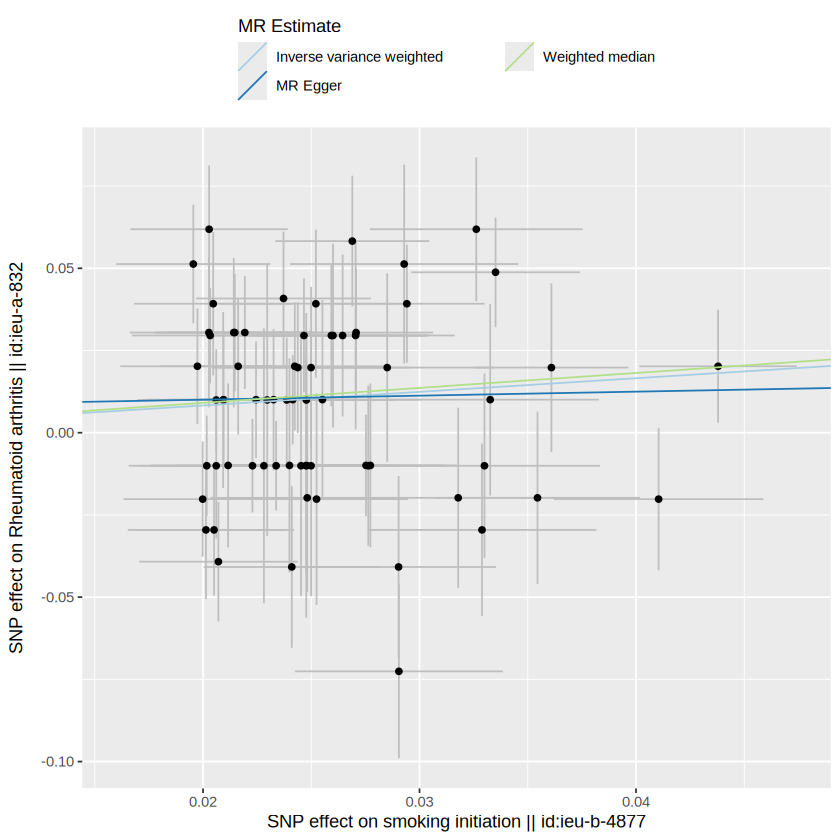

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


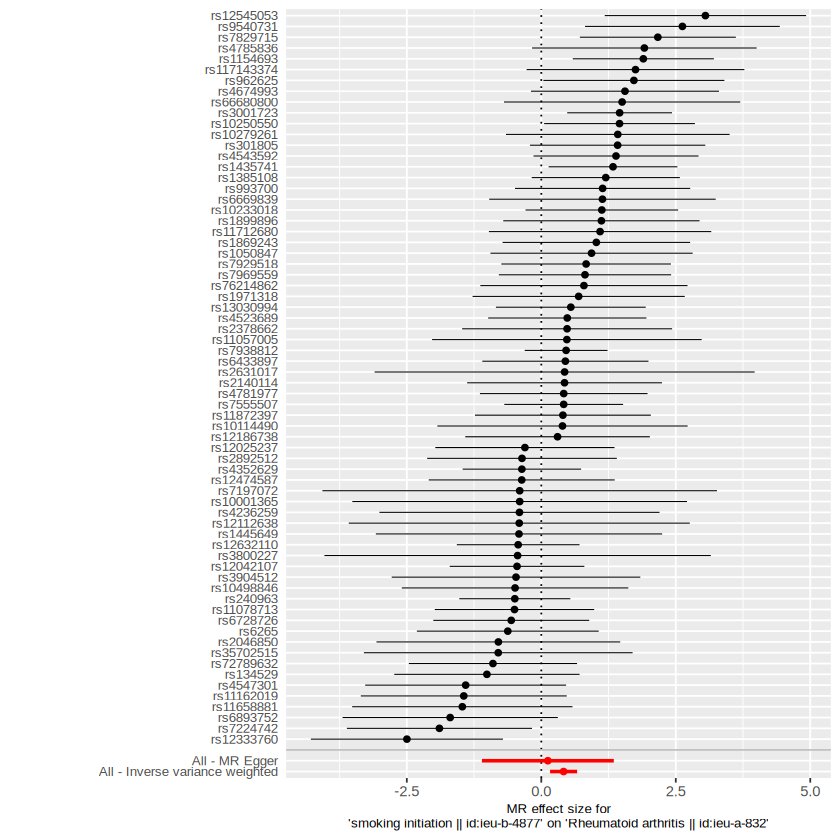

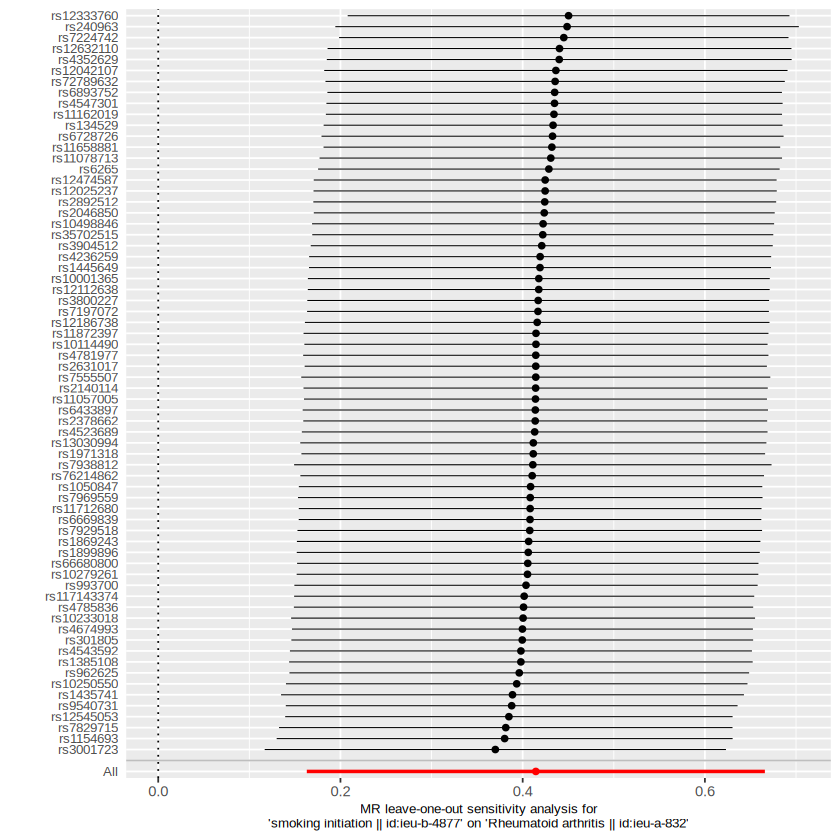

In [10]:
names(results)
target <- "smk_ra"

if (target %in% names(results)) {
  x  <- results[[target]]
  p1 <- mr_scatter_plot(mr(x$dat, method_list = c("mr_ivw", "mr_egger_regression",
                                                  "mr_weighted_median")), x$dat)[[1]]
  p2 <- mr_forest_plot(mr_singlesnp(x$dat))[[1]]
  print(p1); print(p2)
  ggsave(paste0("mr_scatter_", target, ".png"), p1, width = 6, height = 5, dpi = 150)
  ggsave(paste0("mr_forest_",  target, ".png"), p2, width = 6, height = 8, dpi = 150)
  if (!is.null(x$loo)) print(mr_leaveoneout_plot(x$loo)[[1]])
}

## 5. 결과 요약 표

In [11]:
summary_tbl <- bind_rows(lapply(results, `[[`, "result")) %>%
  select(question, method, nsnp, or, or_lci95, or_uci95, pval) %>%
  mutate(across(c(or, or_lci95, or_uci95), ~ round(.x, 3)),
         pval = signif(pval, 3))

egger <- bind_rows(lapply(results, function(x)
  if (!is.null(x$pleiotropy)) data.frame(question = x$label,
                                         egger_intercept = round(x$pleiotropy$egger_intercept, 4),
                                         egger_p = signif(x$pleiotropy$pval, 3))))

write.csv(summary_tbl, "mr_summary.csv", row.names = FALSE)
summary_tbl
egger

question,method,nsnp,or,or_lci95,or_uci95,pval
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Smoking -> RA,Inverse variance weighted,68,1.514,1.177,1.946,1.23e-03
Smoking -> RA,MR Egger,68,1.130,0.332,3.848,8.46e-01
Smoking -> RA,Weighted median,68,1.575,1.123,2.210,8.54e-03
Smoking -> RA,Weighted mode,68,1.948,0.933,4.069,8.06e-02
"Smoking -> RA (large GWAS, overlap)",Inverse variance weighted,85,1.165,1.014,1.339,3.14e-02
"Smoking -> RA (large GWAS, overlap)",MR Egger,85,1.023,0.507,2.064,9.49e-01
"Smoking -> RA (large GWAS, overlap)",Weighted median,85,1.212,1.011,1.453,3.72e-02
"Smoking -> RA (large GWAS, overlap)",Weighted mode,85,1.230,0.845,1.789,2.83e-01
BMI -> RA,Inverse variance weighted,427,1.239,1.059,1.451,7.66e-03


question,egger_intercept,egger_p
<chr>,<dbl>,<dbl>
Smoking -> RA,0.0076,0.63400
"Smoking -> RA (large GWAS, overlap)",0.0034,0.71300
BMI -> RA,0.0033,0.33600
"BMI -> RA (large GWAS, overlap)",0.0047,0.01710
RA -> AD,0.0094,0.00729
RA -> AD (no HLA),0.0031,0.54600
SLE -> AD,0.0033,0.49700
SLE -> AD (no HLA),0.0013,0.81200
AD -> RA (reverse),0.0477,0.43400


## 6. 해석 가이드 (README에 정리)
- **IVW, MR-Egger, 가중 중앙값의 방향과 크기가 비슷하면** 다면발현에 비교적 강건하다고 판단합니다.
- **MR-Egger 절편이 유의하면**(p < 0.05) 방향성 다면발현 가능성 → 해석 주의
- **Cochran's Q가 유의하면** 변이 간 효과가 이질적 → 무작위효과 IVW, 가중 중앙값 결과를 함께 제시
- **HLA 제외 전후 결과가 크게 다르면** HLA 다면발현이 결과를 이끌었을 가능성
- **주 분석과 대규모 GWAS(표본 중복) 결과 비교**: 방향이 같으면 결과가 더 믿을 만함. 중복이 있으면 결과가 관찰 연관성 쪽으로 치우칠 수 있음
- 유럽계 GWAS 결과를 한국인에게 그대로 일반화하기 어렵다는 점을 한계로 적습니다. 가능하면 동아시아 GWAS(BBJ 등)로 재현해 봅니다.
- 파트 A(관찰 연관성)와 방향이 다르면, 관찰 결과가 교란이나 역인과의 영향을 받았을 가능성을 논의합니다.